<a href="https://colab.research.google.com/github/juliaBerserk/rea-artificial-intelligence-systems-tasks/blob/main/Untitled2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# На первом этапе импортируем все необходимые модули
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_percentage_error #MAPE
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('boston.csv')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


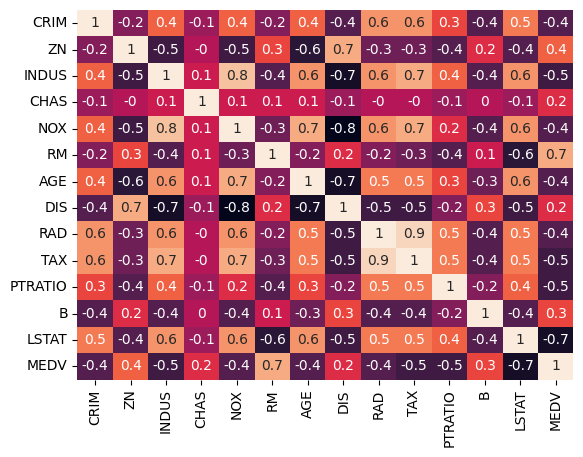

In [9]:
# Построим матрицу корреляции и визуализируем с помощью библиотеки seaborn.
sns.heatmap(df.corr().round(1), annot = True, cbar=False)
plt.show()
# Какие выводы можно сделать по указанному набору данных?

In [10]:
# Разделим случайным образом нашу выборку на тестовую и обучающую. Для этого используем функцию train_test_split библиотеки Scikit learn.
x_train, x_test, y_train, y_test = train_test_split(df[['LSTAT', 'RM']], df['MEDV'], train_size = 0.9, random_state=3)

In [11]:
# Настраиваем нейронную сеть. В нашей сети будет 2 слоя, на внутреннем слое используем функцию selu, на выходном – linear. Подробнее о существующих в библиотеке функциях активации читайте в документации.

model = keras.Sequential([
      layers.Dense(10, activation='selu'),
      layers.Dense(1, activation='linear')
    ])

In [18]:
# Выберем алгоритм обучения. В учебном примере используем алгоритм Adam. В качестве функции потерь на каждой эпохе будем рассчитывать среднюю относительную ошибку (MAPE). Она наиболее удобная для решения задачи регрессии. В случае решения задачи классификации необходимо использовать метрику accuracy.
model.compile(
    loss='mape',
    optimizer='adam',
    metrics=['mape'])

In [19]:
# Задаем переменную с количеством эпох.
EPOCHS=80

In [20]:
# Обучим нейронную сеть.
history = model.fit(
          x_train, y_train,
          epochs=EPOCHS,  verbose=2, batch_size=4, validation_split=0.3)

Epoch 1/80
80/80 - 2s - 25ms/step - loss: 100.8321 - mape: 100.8321 - val_loss: 81.8665 - val_mape: 81.8665
Epoch 2/80
80/80 - 0s - 5ms/step - loss: 69.5964 - mape: 69.5964 - val_loss: 61.1615 - val_mape: 61.1615
Epoch 3/80
80/80 - 1s - 8ms/step - loss: 55.9964 - mape: 55.9964 - val_loss: 56.4410 - val_mape: 56.4410
Epoch 4/80
80/80 - 0s - 5ms/step - loss: 50.5041 - mape: 50.5041 - val_loss: 52.7296 - val_mape: 52.7296
Epoch 5/80
80/80 - 0s - 3ms/step - loss: 46.0803 - mape: 46.0803 - val_loss: 49.2678 - val_mape: 49.2678
Epoch 6/80
80/80 - 0s - 4ms/step - loss: 42.9112 - mape: 42.9112 - val_loss: 45.8982 - val_mape: 45.8982
Epoch 7/80
80/80 - 0s - 3ms/step - loss: 39.9334 - mape: 39.9334 - val_loss: 42.4942 - val_mape: 42.4942
Epoch 8/80
80/80 - 0s - 3ms/step - loss: 36.7438 - mape: 36.7438 - val_loss: 38.8806 - val_mape: 38.8806
Epoch 9/80
80/80 - 0s - 3ms/step - loss: 33.4271 - mape: 33.4271 - val_loss: 35.1331 - val_mape: 35.1331
Epoch 10/80
80/80 - 0s - 3ms/step - loss: 30.1870 - 

In [22]:
# Реализуем прогнозирование и рассчитаем MAPE на тестовой выборке.
y_pred = model.predict(x_test)
print(mean_absolute_percentage_error(y_test, y_pred))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
0.16164469846010668


**Задание 1**

**Задание 2**